# Gear dynamics 01: the rigid mesh, its forces and reaction points

**Series:** gear dynamics in small steps, from a perfectly rigid tooth contact to a
flexible shaft-bearing-gear system with backlash.

| # | notebook | adds |
|---|---|---|
| **01** | **rigid mesh** | **kinematics, reduced inertia, mesh force, bearing reactions, helical statics** |
| 02 | mesh stiffness and damping | the mesh becomes a spring-damper along the line of action |
| 03 | time-varying mesh stiffness | tooth-pair alternation, transmission error, speed sweeps, parametric stability |
| 04 | backlash | two flanks, impacts, rattle, jump phenomena |
| 05 | bearings and lateral DOFs | gear centres move, coupled torsion-lateral modes, dynamic bearing forces |
| 06 | flexible shafts | shaft finite elements, rigid vs torsion vs bending flexibility, wind-up release |

All notebooks share `geardyn.py` and one illustrative **reference pair**
(24/48 teeth, module 2.5 mm, 20°, 15 mm face). The numbers are round and plausible,
**not** data of a real gearbox.

**This notebook (about 30 min):** everything you can know about a gear pair *before* any
flexibility enters. That turns out to be a lot: the force direction, the split between
load and inertia force, what each bearing sees, and what the housing has to react.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp
import geardyn as gd

gd.style()
gp = gd.GearPair()
print(gp.summary())

z1 / z2                                 24 / 48  -
ratio i = z2/z1                           2.000  -
module                                     2.50  mm
pressure angle                             20.0  deg
pitch radii r1 / r2               30.00 / 60.00  mm
base radii rb1 / rb2              28.19 / 56.38  mm
centre distance a                         90.00  mm
base pitch pb                             7.380  mm
contact ratio eps_alpha                   1.675  -
J1 / J2                   1.498e-04 / 2.397e-03  kg m^2
m1 / m2                           0.333 / 1.332  kg
equivalent mass m_eq                     0.1508  kg
mesh stiffness k (mean)                   316.3  N/um
mesh damping c                            690.6  N s/m
mesh natural frequency                     7288  Hz
backlash j_n                                  0  um


## 1  Geometry in one picture

An involute flank is the curve traced by a taut string unwound from the **base circle**
($r_b = r\cos\alpha$). Two consequences carry the whole of gear dynamics:

1. The contact point always lies on the **line of action** (LOA), the common tangent of the
   two base circles. The normal force therefore has a **fixed direction**, tilted by the
   pressure angle $\alpha$ against the common tangent of the pitch circles.
2. Its lever arm about each centre is the **base radius**, constant through the mesh.
   So the rigid ratio is exactly constant: $i = r_{b2}/r_{b1} = z_2/z_1$.

Sign conventions used throughout the series (also in the `geardyn` docstring):

* gear 1 at the origin, gear 2 at $(a, 0)$, shafts along $+z$;
* $\theta_1$ counter-clockwise positive, $\theta_2$ **clockwise** positive, so both grow in
  forward running;
* **drive flank**: gear 1 pushes gear 2. Unit vector of the force on gear 2
  $\mathbf n_d = (\sin\alpha, \cos\alpha)$; the coast flank uses $\mathbf n_r = (\sin\alpha, -\cos\alpha)$.
  Both point *away from gear 1*: the tooth force always tries to separate the centres.

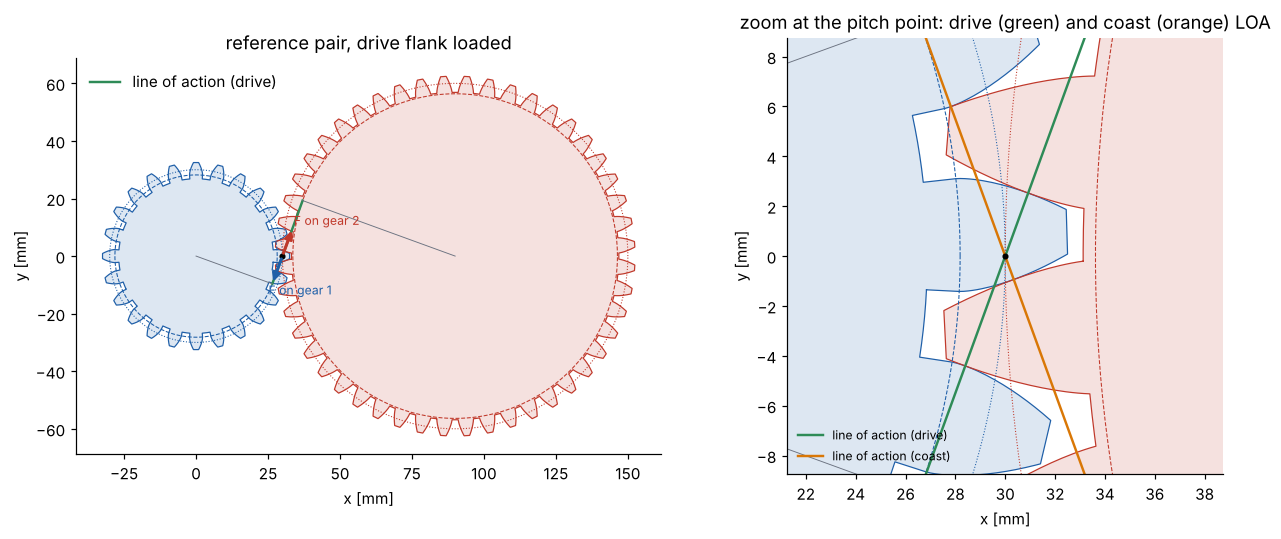

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
gd.draw_pair(ax[0], gp, F=1.0)
ax[0].set_title("reference pair, drive flank loaded")
ax[0].legend(loc="upper left")
gd.draw_pair(ax[1], gp, flank="both", zoom=True, theta1=0.03)
ax[1].set_title("zoom at the pitch point: drive (green) and coast (orange) LOA")
ax[1].legend(loc="lower left", fontsize=8)
plt.tight_layout()

### Contact ratio: how many tooth pairs carry load

The contact point travels along the LOA at speed $r_{b1}\omega_1$. The active part of the LOA
(between the two tip circles) has length $g_\alpha$; a new pair enters every **base pitch**
$p_b = \pi m\cos\alpha$. The **transverse contact ratio**

$$\varepsilon_\alpha = \frac{g_\alpha}{p_b}
  = \frac{\sqrt{r_{a1}^2-r_{b1}^2}+\sqrt{r_{a2}^2-r_{b2}^2}-a\sin\alpha}{\pi m\cos\alpha}$$

is the mean number of pairs in contact. With $\varepsilon_\alpha = 1.675$, two pairs share
the load for 67.5 % of every mesh cycle and one pair carries it alone for the rest.
A rigid mesh doesn't notice. It becomes the main excitation in notebook 03.

g_alpha = 12.36 mm, p_b = 7.380 mm
mesh frequency at 10 000 rpm: 4000 Hz


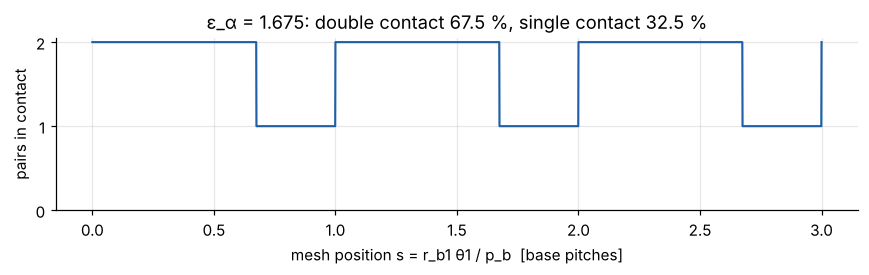

In [3]:
s = np.linspace(0, 3, 3001)                 # mesh position in base pitches
eps = gp.eps_alpha
pairs = np.zeros_like(s)
for k in range(-2, 5):                      # pair k enters at s = k and leaves at s = k + eps
    pairs += ((s >= k) & (s < k + eps))
fig, ax = plt.subplots(figsize=(8, 2.6))
ax.plot(s, pairs, color=gd.C["blue"])
ax.set_xlabel("mesh position s = r_b1 θ1 / p_b  [base pitches]")
ax.set_ylabel("pairs in contact"); ax.set_yticks([0, 1, 2])
ax.set_title(f"ε_α = {eps:.3f}: double contact {100*(eps-1):.1f} %, single contact {100*(2-eps):.1f} %")
plt.tight_layout()
print(f"g_alpha = {gp.path_length*1e3:.2f} mm, p_b = {gp.pb*1e3:.3f} mm")
print(f"mesh frequency at 10 000 rpm: {gp.f_mesh(10000):.0f} Hz")

## 2  Equation of motion of the rigid pair

Two rotations, one constraint ("rolling without loss of contact"):

$$\Phi = r_{b1}\theta_1 - r_{b2}\theta_2 = 0 .$$

**Route A: eliminate.** With $\theta_2 = \theta_1/i$ the kinetic energy is
$T = \tfrac12\left(J_1 + J_2/i^2\right)\dot\theta_1^2$, and Lagrange gives one ODE:

$$\underbrace{\left(J_1+\frac{J_2}{i^2}\right)}_{J_\text{red}}\ddot\theta_1 = T_1 - \frac{T_2}{i}$$

with $T_1$ the drive torque on gear 1 and $T_2$ the load torque on gear 2 (opposing its rotation).

**Route B: keep the constraint (the MBS way).** Add a Lagrange multiplier. The constraint
force on the coordinates is $-\Phi_q^T\lambda$ with $\Phi_q = [r_{b1}, -r_{b2}]$:

$$\begin{bmatrix}J_1 & 0 & r_{b1}\\ 0 & J_2 & -r_{b2}\\ r_{b1} & -r_{b2} & 0\end{bmatrix}
  \begin{bmatrix}\ddot\theta_1\\ \ddot\theta_2\\ \lambda\end{bmatrix} =
  \begin{bmatrix}T_1\\ -T_2\\ 0\end{bmatrix}$$

The multiplier **is the normal tooth force** $F$: it enters gear 1 with arm $r_{b1}$ and
gear 2 with arm $r_{b2}$. This is the same "reactions are multipliers" idea as in the
slider-crank hand-vs-MBS notebook. Let sympy confirm that both routes agree:

In [4]:
J1, J2, rb1, rb2, T1s, T2s = sp.symbols("J_1 J_2 r_b1 r_b2 T_1 T_2", positive=True)
A = sp.Matrix([[J1, 0, rb1], [0, J2, -rb2], [rb1, -rb2, 0]])
x = A.LUsolve(sp.Matrix([T1s, -T2s, 0]))
a1, a2, lam = [sp.simplify(e) for e in x]
i_ = rb2 / rb1
display(sp.Eq(sp.Symbol("ddot theta_1"), a1))
display(sp.Eq(sp.Symbol("F=lambda"), sp.simplify(lam)))
print("route A == route B:", sp.simplify(a1 - (T1s - T2s / i_) / (J1 + J2 / i_**2)) == 0)

Eq(ddot theta_1, r_b2*(T_1*r_b2 - T_2*r_b1)/(J_1*r_b2**2 + J_2*r_b1**2))

Eq(F=lambda, (J_1*T_2*r_b2 + J_2*T_1*r_b1)/(J_1*r_b2**2 + J_2*r_b1**2))

route A == route B: True


Read the mesh force in a more useful form. From the free body of gear 2,
$J_2\ddot\theta_2 = F r_{b2} - T_2$, so

$$F = \underbrace{\frac{T_2}{r_{b2}}}_{\text{load}} + \underbrace{\frac{J_2\ddot\theta_2}{r_{b2}}}_{\text{accelerating gear 2 and everything behind it}}$$

The tooth only carries the torque that the *driven* side needs. During acceleration the
inertia term can be larger than the load term. That is why clutch engagement and launches
often size the gears rather than the rated torque.

## 3  Experiment: run-up, steady state and engine braking

Put a heavy "downstream" inertia on gear 2 (clutch basket, gearbox input, say
$J_{2,\text{extra}} = 0.05$ kg m²) and a fan-type load $T_2 = c\,\omega_2^2$ tuned so the
pair settles at 12 000 rpm with $T_1 = 40$ N m. After one second the throttle closes:
$T_1 = -15$ N m (engine braking). The rigid model is one ODE; the mesh force follows
algebraically.

static check at 12 000 rpm: F = T1/r_b1 = 1419 N, F(t=0.95 s) = 1418 N
start: F = 1403 N, all of it accelerates the load; T1 J2/(i J_red) / r_b2 check = 1403 N


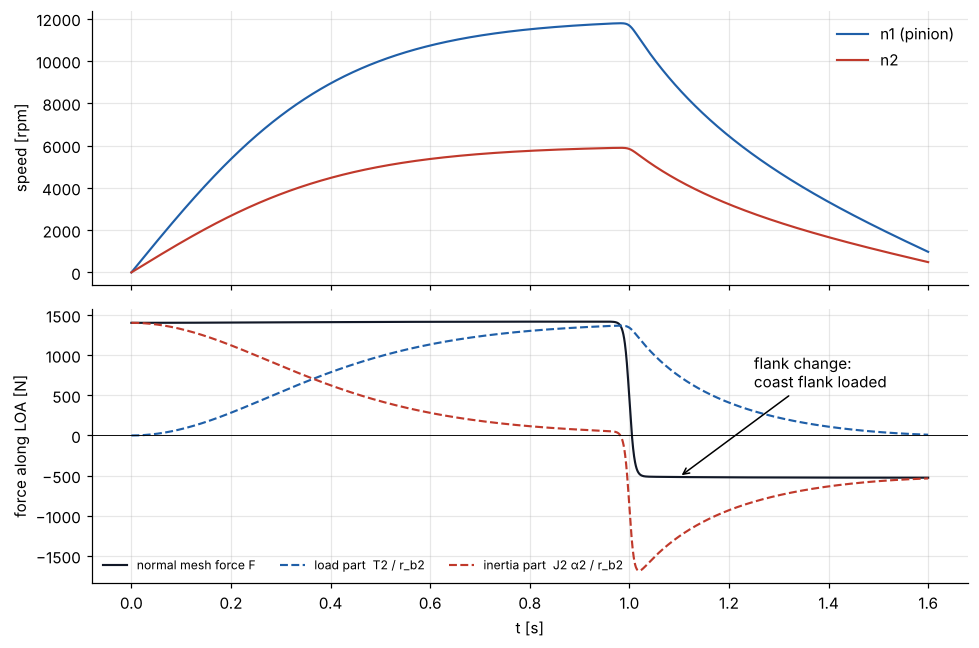

In [5]:
g1 = gp.with_(J2_extra=0.05)
T_drive, T_brake, n_ss = 40.0, -15.0, 12000.0
w2_ss = n_ss * 2 * np.pi / 60 / g1.i
c_fan = g1.i * T_drive / w2_ss**2


def T1_of_t(t):        # smooth 20 ms throttle-off transition at t = 1.0 s
    return T_drive + (T_brake - T_drive) * 0.5 * (1 + np.tanh((t - 1.0) / 0.01))


def rhs(t, y):
    w1 = y[1]; w2 = w1 / g1.i
    a1, _, _ = gd.rigid_pair(g1, T1_of_t(t), c_fan * w2 * abs(w2))
    return [w1, a1]


t = np.linspace(0, 1.6, 3201)
sol = solve_ivp(rhs, (0, 1.6), [0, 0], t_eval=t, rtol=1e-9, max_step=2e-3)
w1 = sol.y[1]; w2 = w1 / g1.i
T2 = c_fan * w2 * np.abs(w2)
a1, a2, F = gd.rigid_pair(g1, T1_of_t(t), T2)
F_load = T2 / g1.rb2; F_inert = g1.J2 * a2 / g1.rb2

fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax[0].plot(t, w1 * 60 / (2 * np.pi), label="n1 (pinion)")
ax[0].plot(t, w2 * 60 / (2 * np.pi), label="n2")
ax[0].set_ylabel("speed [rpm]"); ax[0].legend()
ax[1].plot(t, F, color=gd.C["black"], label="normal mesh force F")
ax[1].plot(t, F_load, "--", label="load part  T2 / r_b2")
ax[1].plot(t, F_inert, "--", label="inertia part  J2 α2 / r_b2")
ax[1].axhline(0, color="k", lw=0.6)
ax[1].set_ylabel("force along LOA [N]"); ax[1].set_xlabel("t [s]"); ax[1].legend(ncol=3, fontsize=8)
ax[1].annotate("flank change:\ncoast flank loaded", xy=(1.1, F[t.searchsorted(1.1)]),
               xytext=(1.25, 600), arrowprops=dict(arrowstyle="->"))
plt.tight_layout()
print(f"static check at 12 000 rpm: F = T1/r_b1 = {T_drive/g1.rb1:.0f} N, "
      f"F(t=0.95 s) = {F[t.searchsorted(0.95)]:.0f} N")
print(f"start: F = {F[0]:.0f} N, all of it accelerates the load; T1 J2/(i J_red) / r_b2 check "
      f"= {T_drive*g1.J2/(g1.i*(g1.J1+g1.J2/g1.i**2))/g1.rb2:.0f} N")

Things to notice:

* At $t = 0$ the whole tooth force accelerates gear 2. Because $J_1 \ll J_2/i^2$, almost all
  of $T_1$ passes through the mesh even though nothing is being "loaded".
* In steady state $F = T_1/r_{b1}$: the inertia term has died out.
* With the throttle closed the sign of $F$ flips. The **coast flank** now carries the load and
  the force direction jumps from $\mathbf n_d$ to $\mathbf n_r$. With backlash (notebook 04)
  this is where the teeth separate, cross the gap and impact.

## 4  Reaction points: from tooth force to bearing forces

**Components at the gear.** Force on gear 2 (gear 1 sees the opposite):

$$F_x = |F|\sin\alpha \;\;(\text{separating, always positive}),\qquad
  F_y = F\cos\alpha \;\;(\text{tangential} = T/r).$$

The tangential part $F_t = F\cos\alpha = T_1/r_1$ is the familiar "torque over pitch radius".
The **total** normal force is larger by $1/\cos\alpha$ (6 % at 20°), and the bearings
see that total.

**Shaft statics.** Each shaft rests on a locating bearing A and a floating bearing B.
With the gear at axial position $z_g$ the reactions follow from force and moment
equilibrium. The problem is statically determinate, so bearing *stiffness* plays no part
here. That stays true in notebook 06 with fully flexible shafts.

$$\mathbf R_B = -\frac{z_g - z_A}{L}\,\mathbf F_\perp ,\qquad \mathbf R_A = -\mathbf F_\perp - \mathbf R_B$$

(for an axial force there is an extra couple; see section 5). Layout: A at $z=0$, gear at
25 mm, B at 80 mm, the same on both shafts.

bearing 1A force direction: drive 70.0 deg, coast -70.0 deg -> the direction jumps by 180 - 2*alpha = 140 deg


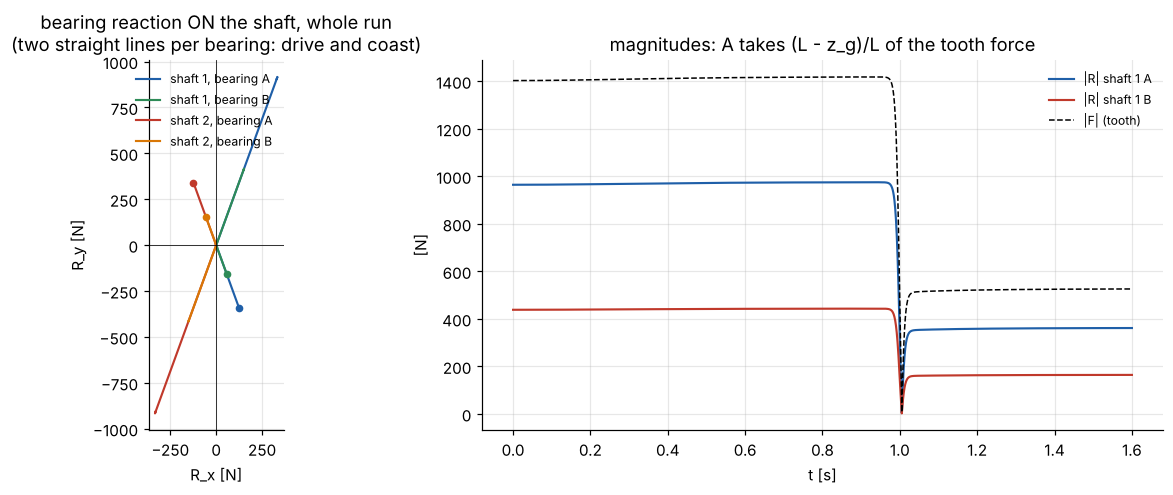

In [6]:
zA, zg, zB = 0.0, 0.025, 0.080
Fx2, Fy2 = gd.mesh_force_on_gear2(F, gp.alpha)
# shaft 1 carries the force on gear 1 = -(force on gear 2); contact at the pitch point (r1, 0)
RA1, RB1 = gd.shaft_bearing_reactions((-Fx2, -Fy2, 0 * F), (gp.r1, 0, zg), zA, zB)
RA2, RB2 = gd.shaft_bearing_reactions((Fx2, Fy2, 0 * F), (-gp.r2, 0, zg), zA, zB)

fig = plt.figure(figsize=(12, 4.6))
axp = fig.add_subplot(1, 2, 1)
for R, lab, col in [(RA1, "shaft 1, bearing A", gd.C["blue"]), (RB1, "shaft 1, bearing B", gd.C["green"]),
                    (RA2, "shaft 2, bearing A", gd.C["red"]), (RB2, "shaft 2, bearing B", gd.C["orange"])]:
    axp.plot(R[0], R[1], color=col, label=lab)
    axp.plot(R[0][-1], R[1][-1], "o", color=col, ms=4)
axp.set_aspect("equal"); axp.axhline(0, color="k", lw=.5); axp.axvline(0, color="k", lw=.5)
axp.set_xlabel("R_x [N]"); axp.set_ylabel("R_y [N]")
axp.set_title("bearing reaction ON the shaft, whole run\n(two straight lines per bearing: drive and coast)")
axp.legend(fontsize=8)
ax2 = fig.add_subplot(1, 2, 2)
ax2.plot(t, np.hypot(RA1[0], RA1[1]), label="|R| shaft 1 A")
ax2.plot(t, np.hypot(RB1[0], RB1[1]), label="|R| shaft 1 B")
ax2.plot(t, np.abs(F), "k--", lw=1, label="|F| (tooth)")
ax2.set_xlabel("t [s]"); ax2.set_ylabel("[N]"); ax2.legend(fontsize=8)
ax2.set_title("magnitudes: A takes (L - z_g)/L of the tooth force")
plt.tight_layout()

ang_d = np.degrees(np.arctan2(RA1[1][1500], RA1[0][1500]))
ang_c = np.degrees(np.arctan2(RA1[1][-1], RA1[0][-1]))
print(f"bearing 1A force direction: drive {ang_d:.1f} deg, coast {ang_c:.1f} deg "
      f"-> the direction jumps by 180 - 2*alpha = {180-2*gp.alpha_deg:.0f} deg")

### What the housing has to react

The bearing forces on the two shafts are equal and opposite, but they act on **different
lines**, so together they form a couple: $|F|$ times the distance between the two parallel
lines of action through the centres, which is $a\cos\alpha = r_{b1}+r_{b2}$. In steady state

$$M_\text{housing} = F\,(r_{b1}+r_{b2}) = T_1 + T_2 = T_1(1+i) .$$

This is the gearbox **reaction torque**. A rigid pair does not conserve angular momentum,
because the housing keeps exchanging torque with it. In notebook 02 you will see what *is*
conserved instead.

In [7]:
k = t.searchsorted(0.95)
# moment about the origin of all bearing forces on the shafts (shaft 2 axis at x = a)
Mz = (gp.a * (RA2[1][k] + RB2[1][k]))   # shaft-1 reactions pass through the origin
dHdt = g1.J1 * a1[k] - g1.J2 * a2[k]      # rate of physical angular momentum (gear 2 turns CW)
print(f"moment of bearing reactions on the shafts       : {Mz:8.2f} N m")
print(f"-(T1 + T2) + dH/dt at 0.95 s                    : {-(T1_of_t(t[k]) + T2[k]) + dHdt:8.2f} N m")
print(f"   of which -(T1+T2) = {-(T1_of_t(t[k]) + T2[k]):.2f} N m, still-accelerating part dH/dt = {dHdt:.2f} N m")

moment of bearing reactions on the shafts       :  -119.94 N m
-(T1 + T2) + dH/dt at 0.95 s                    :  -119.94 N m
   of which -(T1+T2) = -116.73 N m, still-accelerating part dH/dt = -3.20 N m


## 5  Helical gears: axial force and tilting couple (statics only)

A helix angle $\beta$ tilts the normal force out of the transverse plane:

$$F_t = \frac{T_1}{r_1},\quad F_r = F_t\tan\alpha_t,\quad F_a = F_t\tan\beta,\qquad
  \tan\alpha_t = \frac{\tan\alpha_n}{\cos\beta}$$

The axial force acts at the pitch radius, so it creates a **tilting moment** $F_a r$ about the
radial axis. The locating bearing takes $F_a$ axially, and both bearings get an extra
radial couple $\pm F_a r / L$. Helical gears run quieter (overlap ratio, notebook 03) but
shift load from the radial into the axial bearing. The spur dynamics in this series stay
planar.

beta = 25 deg: F_a = 622 N, tilting moment F_a r1 = 18.7 N m


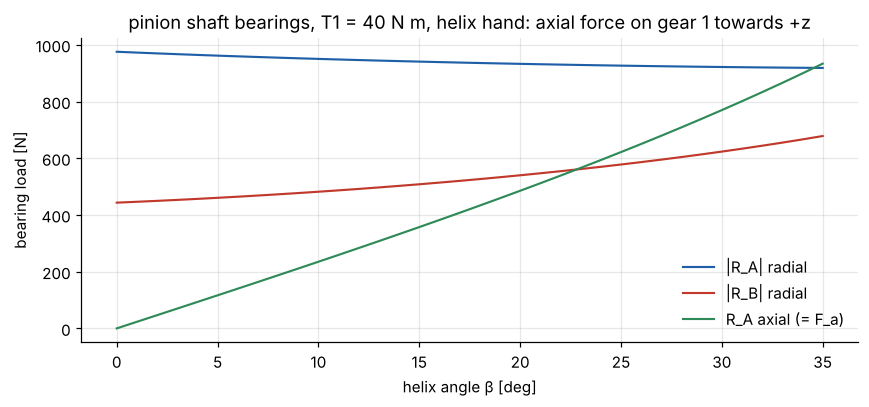

In [8]:
T1 = 40.0
betas = np.linspace(0, 35, 36)
out = []
for b in np.radians(betas):
    at = np.arctan(np.tan(gp.alpha) / np.cos(b))
    Ft = T1 / gp.r1; Fr = Ft * np.tan(at); Fa = Ft * np.tan(b)
    # force on gear 1 at its pitch point (r1, 0, zg): tangential -y, radial -x, axial +z
    RA, RB = gd.shaft_bearing_reactions((-Fr, -Ft, Fa), (gp.r1, 0, zg), zA, zB)
    out.append([np.hypot(*RA[:2]), np.hypot(*RB[:2]), abs(RA[2]), Fa * gp.r1])
out = np.array(out)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(betas, out[:, 0], label="|R_A| radial")
ax.plot(betas, out[:, 1], label="|R_B| radial")
ax.plot(betas, out[:, 2], label="R_A axial (= F_a)")
ax.set_xlabel("helix angle β [deg]"); ax.set_ylabel("bearing load [N]")
ax.set_title("pinion shaft bearings, T1 = 40 N m, helix hand: axial force on gear 1 towards +z")
ax.legend()
plt.tight_layout()
print(f"beta = 25 deg: F_a = {out[25,2]:.0f} N, tilting moment F_a r1 = {out[25,3]:.1f} N m")

Bearing B gains load and bearing A loses it (or the other way round for the opposite hand or
load direction). Flip the sign of `Fa` and see. Many motorcycle primary drives use helical
or straight-cut gears depending on whether noise or bearing life and axial packaging matter more.

## 6  Take-aways

* The tooth force has a **fixed direction**, the line of action. Its magnitude is
  $F = T/r_b$ (not $T/r$), and it always pushes the centres apart.
* Rigid mesh = one constraint. The constraint multiplier **is** the normal force. Dynamically
  $F = (T_2 + J_2\ddot\theta_2)/r_{b2}$: load plus the inertia of everything behind gear 2.
* Reversing the torque flips the loaded flank. The bearing-force direction jumps by
  $180° - 2\alpha$ and the tangential part changes sign, while the separating part stays.
* Bearing reactions follow from statics (determinate). The housing reacts $T_1+T_2$.
* Missing so far: the mesh has **no stiffness**, so no vibration, no transmission error and no
  impacts. That comes next.

## Exercises

1. Move the gear on shaft 1 to $z_g = 70$ mm (close to B) and then outboard ($z_g = 100$ mm).
   What happens to bearing A? (Overhung gear: A changes sign.)
2. Change the pressure angle to 25°. How much do the separating force and the bearing loads
   grow for the same torque?
3. In the run-up, put the extra inertia on gear 1 instead (`J1_extra=0.0125`, same reduced
   inertia). Why does the start-up mesh force almost vanish?
4. Use sympy to add a third gear (an idler) with two constraints. Show that the idler's
   bearing force is the **vector sum** of two tooth forces, and that its size depends on the
   angle between the two centre lines.